In [2]:
def add_scale_bar(ax, length_km=50, loc=(0.005, 0.005)):
    """Draw a scale bar of length_km on an Axes whose coordinates are in metres."""
    x0, x1 = ax.get_xlim()
    y0, y1 = ax.get_ylim()
    x = x0 + loc[0] * (x1 - x0)
    y = y0 + loc[1] * (y1 - y0)
    ax.plot([x, x + length_km * 1000], [y, y], color="black", lw=3)
    ax.text(x + length_km * 500, y + 0.015 * (y1 - y0), f"{length_km} km", ha="center", va="bottom", fontsize=9)


def add_north_arrow(ax, loc=(0.98, 0.95)):
    ax.annotate("N", xy=loc, xytext=(loc[0], loc[1] - 0.1), xycoords="axes fraction",
                ha="center", va="center", fontsize=12, fontweight="bold",
                arrowprops={"arrowstyle": "-|>", "color": "black"})

In [4]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt

df=gpd.read_file("../../Speculation-Map/Data/Pol/Mean_price.csv")
municipis=gpd.read_file("../../Speculation-Map/Data/divisions-administratives-v2r1-municipis-1000000-20250730.json").to_crs(25831)
#municipis.plot()
df.head(80)

,Àmbit territorial,Codi territorial,Nom territori,Any,Període,Habitatges,Renda,Tram de preus
0,Municipi,08001,Abrera,2026,gener-juny,62,"783,62",> 600 euros/mes
1,Municipi,25002,Àger,2026,gener-juny,7,"384,29",> 350 i <= 450 euros/mes
2,Municipi,25003,Agramunt,2026,gener-juny,39,"474,23",> 450 i <= 600 euros/mes
3,Municipi,17001,Agullana,2026,gener-juny,5,,> 600 euros/mes
4,Municipi,08014,Aiguafreda,2026,gener-juny,23,"688,46",> 600 euros/mes
...,...,...,...,...,...,...,...,...
75,Municipi,25041,Barbens,2026,gener-juny,3,,> 350 i <= 450 euros/mes
76,Municipi,43021,Barberà de la Conca,2026,gener-juny,2,,> 350 i <= 450 euros/mes
77,Municipi,08252,Barberà del Vallès,2026,gener-juny,98,"855,52",> 600 euros/mes
78,Municipi,08019,Barcelona,2026,gener-juny,16.001,"1.139,09",> 600 euros/mes


In [5]:
df["Renda"]

0        783,62
1        384,29
2        474,23
3              
4        688,46
          ...  
47536          
47537          
47538          
47539          
47540    268,57
Name: Renda, Length: 47541, dtype: str

In [6]:
def string_to_float(s):
    return pd.to_numeric(s.astype(str)
    .str.replace('.', '', regex=False)
    .str.replace(',', '.', regex=False), errors='coerce')
    

In [7]:
cols = ['Renda', 'Habitatges']
df[cols] = df[cols].apply(string_to_float)

In [8]:
df["Renda"]

0        783.62
1        384.29
2        474.23
3           NaN
4        688.46
          ...  
47536       NaN
47537       NaN
47538       NaN
47539       NaN
47540    268.57
Name: Renda, Length: 47541, dtype: float64

In [9]:
def string_to_float_2(s):
    return pd.to_numeric(s
    , errors='coerce')

947 947


,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry,ine5,renda,habitatges,habit_per_inhab
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",08001,684.226094,88.0,0.006663
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",08002,NaN,1.0,0.003413
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",08003,1208.400469,75.0,0.007316
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",08004,327.590000,2.0,0.007491
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",08005,990.379062,39.0,0.004117


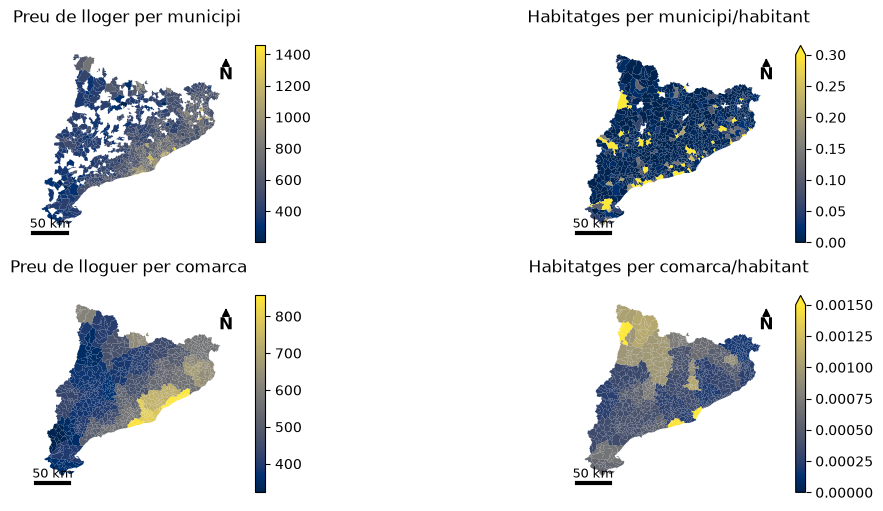

In [10]:
code_municipi=df["Codi territorial"]
mean_rent=df["Renda"]
number_rents=df["Habitatges"]

# The municipality code is not the same in both data sets. In the map coordinates, the code is 6 digits long
# (the sixth digit is a check digit). In the mean price data, the code is five digits long (INE 5). We take out the check digit
# from the map coordinates set and then merge the dataset using the municipality code.

municipis["ine5"]=municipis["CODIMUNI"].str[:5]
df["ine5"]=df["Codi territorial"]

############################################################## INHABITANTS

habitants=gpd.read_file("../../Speculation-Map/Data/Habitants.csv")

habitants["value"]=habitants["value"].apply(string_to_float_2)

total_hab_mun=habitants.groupby("MUN",as_index=False).agg(inhabitants=("value", lambda s: s.sum()/2))
total_hab_mun["ine5"]=total_hab_mun["MUN"].str[:5]

total_hab_com_1=total_hab_mun.merge(municipis[["ine5","CODICOMAR"]],on="ine5",how="left",validate="many_to_one")
total_hab_com_2=total_hab_com_1.groupby("CODICOMAR",as_index=False).agg(inhab_com=("inhabitants",lambda s: s.sum()))
total_hab_com=municipis.merge(total_hab_com_2,on="CODICOMAR",how="left",validate="many_to_one")

###############################################################

df_2026=df[df["Any"]=="2026"]
df_2026_mean=df.groupby("ine5",as_index=False).agg(renda_2026=("Renda", lambda s: s.mean()))
df_26=df.merge(df_2026_mean,on="ine5",how="left",validate="many_to_one")


per_municipi_2026=df_26.groupby("ine5",as_index=False).agg(renda=("Renda", lambda s: s.mean()) ,habitatges=("Habitatges", lambda s: s.mean() ))
per_municipi_2026["habitatges"]=per_municipi_2026["habitatges"].astype(int)
merged_municipi_2026=municipis.merge(per_municipi_2026,on="ine5",how="left",validate="one_to_one")

merged_municipi_2026["habit_per_inhab"]=merged_municipi_2026["habitatges"]/total_hab_mun["inhabitants"]


df_comarca=df_26.merge(municipis[["ine5","CODICOMAR"]],on="ine5",how="left",validate="many_to_one")

per_comarca_2026 = df_comarca.groupby("CODICOMAR", as_index=False).agg(renda=("Renda", lambda s: s.mean() ),habitatges=("Habitatges", lambda s: s.mean() ))
per_comarca_2026["habitatges"]=per_comarca_2026["habitatges"].astype(int)

merged_comarca_2026=municipis.merge(per_comarca_2026,on="CODICOMAR",how="left",validate="many_to_one")
print(len(merged_comarca_2026["renda"]),len(total_hab_com["inhab_com"]))

merged_comarca_2026["habit_per_inhab"]=merged_comarca_2026["habitatges"]/total_hab_com["inhab_com"]


fig, axs = plt.subplots(2,2,figsize=(11, 5), layout="constrained")

merged_municipi_2026.plot(column="renda",cmap="cividis",legend=True,ax=axs[0][0])
merged_municipi_2026.plot(column="habit_per_inhab",cmap="cividis",vmin=0,vmax=0.3,legend=True,ax=axs[0][1])
merged_comarca_2026.plot(column="renda",cmap="cividis",legend=True,ax=axs[1][0])
merged_comarca_2026.plot(column="habit_per_inhab",cmap="cividis",vmin=0,vmax=0.0015,legend=True,ax=axs[1][1])

axs[0][0].set_title("Preu de lloger per municipi")
axs[0][1].set_title("Habitatges per municipi/habitant")
axs[1][0].set_title("Preu de lloguer per comarca")
axs[1][1].set_title("Habitatges per comarca/habitant")

for i in axs:
    for ax in i:
        ax.set_axis_off()
        add_scale_bar(ax)
        add_north_arrow(ax)


merged_municipi_2026.head()

In [11]:
df_2026=df[df["Any"]=="2026"]
df_2026_mean=df.groupby("ine5",as_index=False).agg(renda_2026=("Renda", lambda s: s.mean()))
df_2026_mean

,ine5,renda_2026
0,08001,684.226094
1,08002,NaN
2,08003,1208.400469
3,08004,327.590000
4,08005,990.379062
...,...,...
940,43903,399.181852
941,43904,354.047344
942,43905,563.673175
943,43906,477.537187


,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,...,geometry,ine5,Àmbit territorial,Codi territorial,Nom territori,Any,Període,Habitatges,Renda,Tram de preus
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,...,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",08001,Municipi,08001,Abrera,2026,gener-juny,62.0,783.62,> 600 euros/mes
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,...,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",08002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,...,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",08003,Municipi,08003,Alella,2026,gener-juny,50.0,1698.03,> 600 euros/mes
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,...,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",08004,Municipi,08004,Alpens,2026,gener-juny,1.0,NaN,> 600 euros/mes
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,...,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",08005,Municipi,08005,"Ametlla del Vallès, l'",2026,gener-juny,33.0,1061.53,> 600 euros/mes


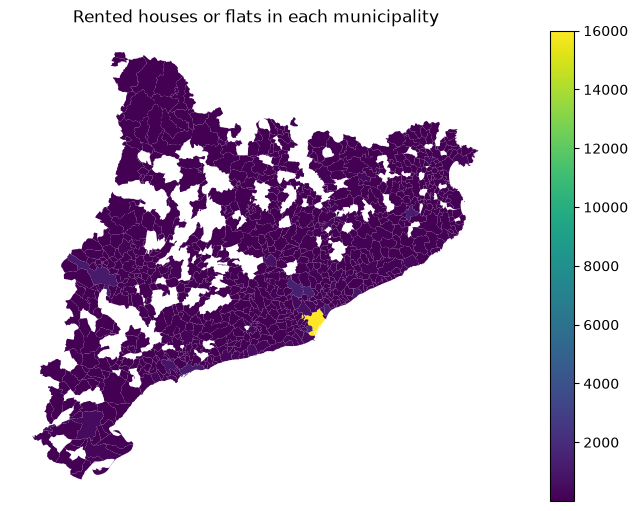

In [12]:
import matplotlib.pyplot as plt

code_municipi=df["Codi territorial"]
mean_rent=df["Renda"]
number_rents=df["Habitatges"]

# The municipality code is not the same in both data sets. In the map coordinates, the code is 6 digits long
# (the sixth digit is a check digit). In the mean price data, the code is five digits long (INE 5). We take out the check digit
# from the map coordinates set and then merge the dataset using the municipality code.

municipis["ine5"]=municipis["CODIMUNI"].str[:5]
df["ine5"]=df["Codi territorial"]

#mean_rent_2026=df.groupby("ine5",as_index=False).agg(renda=("Renda", lambda s: s.sum() ))
mean_rent_2026= df[df["Any"] == "2026"]
mean_rent_mes=mean_rent_2026[mean_rent_2026["Període"]=="gener-juny"]
merged_mes = municipis.merge(mean_rent_mes, on="ine5", how="left", validate="one_to_one")
merged_mes["Habitatges"]=merged_mes["Habitatges"].replace(".","")
#merged_mes["Habitatges"]=merged_mes["Habitatges"].astype(float)

fig, axs = plt.subplots(1,1,figsize=(11, 5), layout="constrained")

merged_mes.plot(column="Habitatges",cmap="viridis",legend=True,ax=axs)

axs.set_title("Rented houses or flats in each municipality")
axs.set_axis_off()
#add_scale_bar(axs)
#add_north_arrow(axs)


merged_mes.head()

## Merge amb Turístics

In [13]:
dataset_csv=gpd.read_file("../../Speculation-Map/Data/Lidia/Turistics.csv")

In [14]:
conteo_municipios = (
    dataset_csv["Codi Municipi (IDESCAT)"]
    .value_counts()
    .reset_index()
)
conteo_municipios.columns = ["Codi Municipi (IDESCAT)", "NombreEdificis"]


conteo_municipios.rename(columns={"Codi Municipi (IDESCAT)": "CODIMUNI"},inplace=True)
print(conteo_municipios)

    CODIMUNI  NombreEdificis
0     080193           11420
1     439057            7204
2     171523            5401
3     430385            3804
4     170470            3690
..       ...             ...
917   250740               1
918   251919               1
919   250411               1
920   250851               1
921   430347               1

[922 rows x 2 columns]


/var/folders/w9/4hxgmht93f3bzp15v7fb90d80000gn/T/ipykernel_7065/2903630879.py:9: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  conteo_municipios.rename(columns={"Codi Municipi (IDESCAT)": "CODIMUNI"},inplace=True)


In [15]:
turistics_municipi = municipis.merge(conteo_municipios, on="CODIMUNI", how="left", validate="one_to_one")
turistics_municipi["ine5"]=turistics_municipi["CODIMUNI"].str[:5]


In [16]:
turistics_hab=turistics_municipi.merge(total_hab_mun,on="ine5",how="left",validate="one_to_one")
turistics_hab["turi_per_inhab"]=turistics_hab["NombreEdificis"]/turistics_hab["inhabitants"]
preu_turistics=merged_municipi_2026.merge(turistics_hab[["NombreEdificis","turi_per_inhab","ine5"]],on="ine5",how="left",validate="one_to_one")

In [17]:
preu_turistics.head()

,CODIMUNI,NOMMUNI,CAPMUNI,AREAM5000,CODICOMAR,NOMCOMAR,CAPCOMAR,CODIVEGUE,NOMVEGUE,CAPVEGUE,CODIPROV,NOMPROV,CAPPROV,geometry,ine5,renda,habitatges,habit_per_inhab,NombreEdificis,turi_per_inhab
0,080018,Abrera,Abrera,19.9781,11,Baix Llobregat,Sant Feliu de Llobregat,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((410315.774 4598888.867, 410075...",08001,684.226094,88.0,0.006663,7.0,0.000530
1,080023,Aguilar de Segarra,Aguilar de Segarra,43.2198,07,Bages,Manresa,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((385155.598 4625034.944, 384697...",08002,NaN,1.0,0.003413,5.0,0.017065
2,080039,Alella,Alella,9.6346,21,Maresme,Mataró,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((440348.026 4596213.927, 440338...",08003,1208.400469,75.0,0.007316,149.0,0.014535
3,080044,Alpens,Alpens,13.7788,43,Lluçanès,Prats de Lluçanès,07,Catalunya Central,*,08,Barcelona,Barcelona,"MULTIPOLYGON (((425142.962 4665930.715, 424829...",08004,327.590000,2.0,0.007491,15.0,0.056180
4,080057,l'Ametlla del Vallès,l'Ametlla del Vallès,14.0885,41,Vallès Oriental,Granollers,01,Barcelona,Barcelona,08,Barcelona,Barcelona,"MULTIPOLYGON (((436871.133 4617049.619, 436914...",08005,990.379062,39.0,0.004117,31.0,0.003272


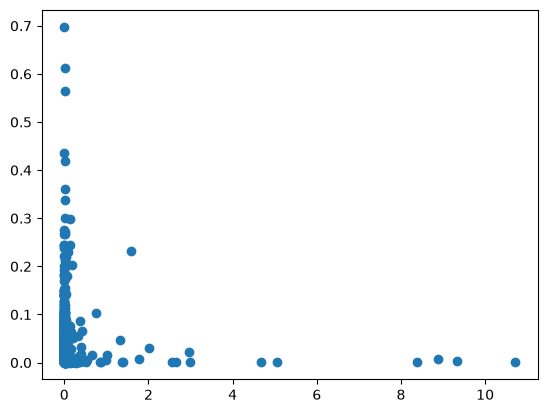

In [19]:
plt.plot(preu_turistics["habit_per_inhab"],preu_turistics["turi_per_inhab"],'o')